<a href="https://colab.research.google.com/github/marizete21/Desafio-Trilhas-2-2026-/blob/main/desafio_trilhas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1: Upload, leitura e diagnóstico inicial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()
arquivo = list(uploaded.keys())[0]

xls = pd.ExcelFile(arquivo)
print("Abas encontradas:", xls.sheet_names)

df = pd.read_excel(arquivo, sheet_name="Dados_Mensais")

print(f"\nDimensões: {df.shape[0]} linhas e {df.shape[1]} colunas")
print("\nTipos de dados:")
print(df.dtypes)
print("\nValores ausentes por coluna:")
print(df.isnull().sum())
print(f"\nLinhas duplicadas: {df.duplicated().sum()}")

df.head(10)

Saving geracao_energia_mensal_ago2025.xlsx to geracao_energia_mensal_ago2025 (1).xlsx
Abas encontradas: ['Dados_Mensais', 'Resumo_Diario', 'Dashboard']

Dimensões: 372 linhas e 4 colunas

Tipos de dados:
Number                    int64
Time             datetime64[ns]
Working State            object
PV(W)                     int64
dtype: object

Valores ausentes por coluna:
Number           0
Time             0
Working State    0
PV(W)            0
dtype: int64

Linhas duplicadas: 0


,Number,Time,Working State,PV(W)
0,1,2025-08-01 06:00:00,Online,420
1,2,2025-08-01 07:00:00,Online,15320
2,3,2025-08-01 08:00:00,Online,40470
3,4,2025-08-01 09:00:00,Online,70590
4,5,2025-08-01 10:00:00,Online,85340
5,6,2025-08-01 11:00:00,Online,97480
6,7,2025-08-01 12:00:00,Online,103490
7,8,2025-08-01 13:00:00,Online,96830
8,9,2025-08-01 14:00:00,Online,76490
9,10,2025-08-01 15:00:00,Online,64340


2: Preparação temporal e estatísticas descritivas

In [2]:
df["Time"] = pd.to_datetime(df["Time"])
df["Data"] = df["Time"].dt.date
df["Dia"] = df["Time"].dt.day
df["Hora"] = df["Time"].dt.hour

pv = df["PV(W)"]
q1 = pv.quantile(0.25)
q3 = pv.quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

resumo = pd.Series({
    "Contagem": pv.count(),
    "Média (W)": pv.mean(),
    "Mediana (W)": pv.median(),
    "Moda (W)": pv.mode().iloc[0],
    "Desvio Padrão (W)": pv.std(),
    "Variância": pv.var(),
    "Coef. de Variação (%)": (pv.std() / pv.mean()) * 100,
    "Mínimo (W)": pv.min(),
    "Q1 - 25% (W)": q1,
    "Q3 - 75% (W)": q3,
    "IQR (W)": iqr,
    "Máximo (W)": pv.max(),
    "Amplitude (W)": pv.max() - pv.min(),
    "Assimetria (Skewness)": pv.skew()
})

print(resumo.round(2))
outliers = df[(pv < lim_inf) | (pv > lim_sup)]
print(f"\nOutliers globais (IQR): {len(outliers)}")

Contagem                 3.720000e+02
Média (W)                4.784280e+04
Mediana (W)              4.486000e+04
Moda (W)                 0.000000e+00
Desvio Padrão (W)        3.413756e+04
Variância                1.165373e+09
Coef. de Variação (%)    7.135000e+01
Mínimo (W)               0.000000e+00
Q1 - 25% (W)             1.519750e+04
Q3 - 75% (W)             7.612750e+04
IQR (W)                  6.093000e+04
Máximo (W)               1.185000e+05
Amplitude (W)            1.185000e+05
Assimetria (Skewness)    1.900000e-01
dtype: float64

Outliers globais (IQR): 0


3: Tabela de frequência e investigação de falhas

In [3]:
freq_abs = df["Working State"].value_counts()
freq_rel = df["Working State"].value_counts(normalize=True) * 100

tabela_freq = pd.DataFrame({
    "Frequência Absoluta": freq_abs,
    "Frequência Relativa (%)": freq_rel.round(2)
})
print(tabela_freq)

print("\nEventos fora do estado Online:")
df[df["Working State"] != "Online"][["Number", "Time", "Working State", "PV(W)"]]

               Frequência Absoluta  Frequência Relativa (%)
Working State                                              
Online                         361                    97.04
Standby                          6                     1.61
Offline                          5                     1.34

Eventos fora do estado Online:


,Number,Time,Working State,PV(W)
48,49,2025-08-05 06:00:00,Standby,70
156,157,2025-08-14 06:00:00,Standby,80
167,168,2025-08-14 17:00:00,Standby,40
170,171,2025-08-15 08:00:00,Offline,0
171,172,2025-08-15 09:00:00,Offline,0
172,173,2025-08-15 10:00:00,Offline,0
216,217,2025-08-19 06:00:00,Standby,80
272,273,2025-08-23 14:00:00,Offline,0
273,274,2025-08-23 15:00:00,Offline,0
300,301,2025-08-26 06:00:00,Standby,80


4: Ranking de dias e perfil horário

In [4]:
diario = df.groupby("Data").agg(
    Energia_kWh=("PV(W)", lambda x: x.sum() / 1000),
    Media_W=("PV(W)", "mean"),
    Pico_W=("PV(W)", "max")
).round(2)

print("Top 5 melhores dias (kWh):")
print(diario.sort_values("Energia_kWh", ascending=False).head(5))

print("\nTop 5 piores dias (kWh):")
print(diario.sort_values("Energia_kWh", ascending=True).head(5))

print("\nResumo por hora do dia (W):")
df.groupby("Hora")["PV(W)"].agg(["mean", "median", "std", "min", "max"]).round(2)

Top 5 melhores dias (kWh):
            Energia_kWh   Media_W  Pico_W
Data                                     
2025-08-29       755.33  62944.17  110630
2025-08-20       733.23  61102.50  109370
2025-08-18       727.22  60601.67  111020
2025-08-06       720.52  60043.33  109350
2025-08-09       713.26  59438.33  108840

Top 5 piores dias (kWh):
            Energia_kWh   Media_W  Pico_W
Data                                     
2025-08-19       303.21  25267.50   50700
2025-08-26       332.61  27717.50   59730
2025-08-04       395.22  32935.00   64950
2025-08-05       403.76  33646.67   69050
2025-08-14       433.00  36083.33   70950

Resumo por hora do dia (W):


,mean,median,std,min,max
Hora,,,,,
6,331.29,390.0,135.74,70,500
7,12073.87,13910.0,3428.53,5570,16540
8,30284.84,35160.0,11677.19,0,43170
9,55602.58,60570.0,17673.05,0,76150
10,69690.97,80420.0,23965.15,0,101530
11,80906.77,91860.0,21845.67,33630,109710
12,86692.90,91440.0,24109.84,47700,118500
13,85402.58,94590.0,19034.15,32870,109120
14,68103.55,76490.0,21416.44,0,96350


5: Visualizações para detecção de padrões e anomalias

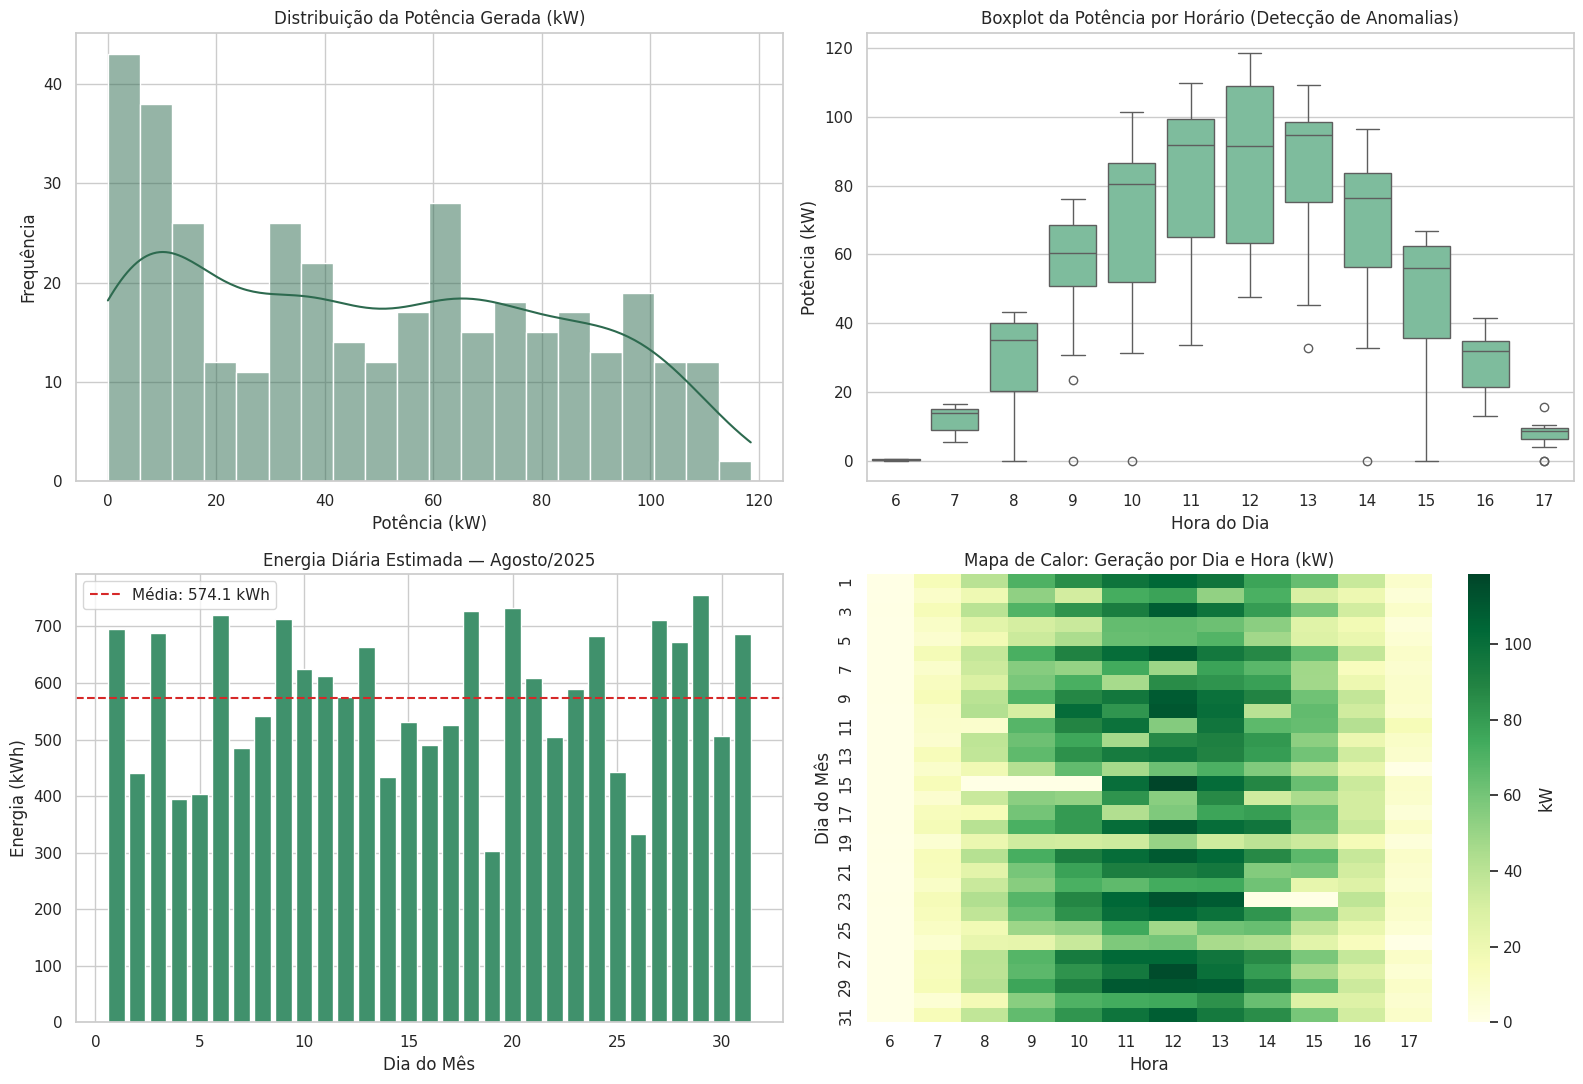

In [5]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(df["PV(W)"] / 1000, bins=20, kde=True, color="#2D6A4F", ax=axes[0, 0])
axes[0, 0].set_title("Distribuição da Potência Gerada (kW)")
axes[0, 0].set_xlabel("Potência (kW)")
axes[0, 0].set_ylabel("Frequência")

sns.boxplot(x="Hora", y=df["PV(W)"] / 1000, data=df, color="#74C69D", ax=axes[0, 1])
axes[0, 1].set_title("Boxplot da Potência por Horário (Detecção de Anomalias)")
axes[0, 1].set_xlabel("Hora do Dia")
axes[0, 1].set_ylabel("Potência (kW)")

diario_plot = df.groupby("Dia")["PV(W)"].sum() / 1000
axes[1, 0].bar(diario_plot.index, diario_plot.values, color="#40916C")
axes[1, 0].axhline(diario_plot.mean(), color="#D62828", linestyle="--", label=f"Média: {diario_plot.mean():.1f} kWh")
axes[1, 0].set_title("Energia Diária Estimada — Agosto/2025")
axes[1, 0].set_xlabel("Dia do Mês")
axes[1, 0].set_ylabel("Energia (kWh)")
axes[1, 0].legend()

matriz = df.pivot(index="Dia", columns="Hora", values="PV(W)") / 1000
sns.heatmap(matriz, cmap="YlGn", ax=axes[1, 1], cbar_kws={"label": "kW"})
axes[1, 1].set_title("Mapa de Calor: Geração por Dia e Hora (kW)")
axes[1, 1].set_xlabel("Hora")
axes[1, 1].set_ylabel("Dia do Mês")

plt.tight_layout()
plt.show()